# 12 — Cantarell: phân lớp, đối chứng và góc tới

Notebook kiểm tra kết quả đã lưu, tính lại metric từ số đếm, vẽ bảng so sánh
và chạy lại một mẫu test với mô hình đã khóa. Không fit hoặc chọn lại theo test.

**Hai tầng đánh giá:** so sánh các cấu hình trên validation; đối chứng NumPy
và thư viện với cùng dữ liệu/định nghĩa. Pipeline chính bị ràng buộc gamma0 +
Niblack để thực hiện yêu cầu góc tới và phân ngưỡng thích nghi. Winner không
ràng buộc cũng được công bố để thấy mức đánh đổi.


In [1]:
from pathlib import Path
import json, sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p/'src/sar_oil').is_dir())
sys.path.insert(0, str(ROOT/'scripts'))
from cantarell_experiment_data import load_manifest, sha, MANIFEST, require_committed
from evaluate_cantarell import scene_bootstrap
from sar_oil.evaluation import summarize
from scripts import streamlit_physical as physical
base = ROOT/'results/cantarell'
manifest, protocol = load_manifest()
selection = json.loads((base/'selection.json').read_text())
required_filter = json.loads((base/'requirements_selection.json').read_text())
validation = json.loads((base/'validation.json').read_text())
evaluation = json.loads((base/'evaluation.json').read_text())
features = json.loads((base/'feature_verification.json').read_text())
bootstrap = json.loads((base/'angle_bootstrap.json').read_text())
assert evaluation['complete'] and validation['complete']
assert not validation['test_accessed'] and not selection['test_accessed']
assert evaluation['binding']['manifest_sha256'] == sha(MANIFEST)
assert evaluation['binding']['selection_sha256'] == sha(base/'selection.json')
assert evaluation['binding']['script_sha256'] == sha(ROOT/'scripts/evaluate_cantarell.py')
assert evaluation['binding']['helper_sha256'] == sha(ROOT/'scripts/train_cantarell.py')
assert selection['validation_sha256'] == sha(base/'validation.json')
assert evaluation['angle_bootstrap_sha256'] == sha(base/'angle_bootstrap.json')
assert len(validation['rows']) == validation['expected_model_pairs']
require_committed(base/'selection.json')
print('Eligible split:', manifest['counts'])
print('Model pairs:', len(validation['rows']))


Eligible split: {'train': 94, 'test': 25, 'val': 35}
Model pairs: 84


## Mọi mô hình và trạng thái hội tụ

Fit scaler bằng train; giữ cùng hàng train cho hai backend. Lấy tối đa 10.000
vùng mỗi lớp, seed 2026; vùng GT giao nhau trung gian chỉ loại trong huấn luyện.
Mô hình lỗi hoặc không hội tụ vẫn có hàng trong bảng, không âm thầm bỏ kết quả.


In [2]:
rows = []
for r in validation['rows']:
    row = {'branch':r['branch'], 'candidate':r['config_id'], 'model':r['model_id'],
           'kind':r['model_config']['kind'], 'eligible':r['eligible'], 'error':r.get('error'),
           'agreement':r.get('classifier_agreement'), 'score_error':r.get('score_max_abs_error')}
    if r['eligible']:
        for backend in ['numpy','reference']:
            assert summarize([i['counts'][backend] for i in r['per_image']]) == r['metrics'][backend]
            row[backend+'_f1'] = r['metrics'][backend]['f1']
            row[backend+'_fit_s'] = r['diagnostics'][backend]['fit_seconds']
            row[backend+'_objective'] = r['diagnostics'][backend].get('objective')
        assert sha(ROOT/r['model_file']) == r['model_sha256']
    rows.append(row)
table = pd.DataFrame(rows)
display(table)
display(pd.DataFrame([{'role':role, 'branch':r['branch'], 'candidate':r['config_id'],
                      'model':r['model_id'], 'validation_f1':r['metrics']['numpy']['f1']}
                     for role,r in selection['winners'].items()]))
print('Required-filter supplement:', required_filter['selected']['config'])
print('Validation F1 tradeoff:', required_filter['validation_f1_difference_from_original_primary'])
print(required_filter['disclosure'])


,branch,candidate,model,kind,eligible,error,agreement,score_error,numpy_f1,numpy_fit_s,numpy_objective,reference_f1,reference_fit_s,reference_objective
0,sigma0,2,0,svm,True,None,1.000000,0.006684,0.102921,0.288389,0.013119,0.102921,0.393777,0.013119
1,sigma0,2,1,svm,True,None,1.000000,0.001345,0.104094,0.361592,0.129778,0.104094,0.022870,0.129778
2,sigma0,2,2,svm,True,None,1.000000,0.000029,0.104094,0.426251,1.296306,0.104094,0.025176,1.296306
3,sigma0,2,3,cart,True,None,1.000000,0.000000,0.084967,0.049564,NaN,0.084967,0.043861,NaN
4,sigma0,2,4,cart,True,None,1.000000,0.000000,0.084967,0.068752,NaN,0.084967,0.064849,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
79,gamma0,22,2,svm,True,None,1.000000,0.000081,0.062810,0.243466,1.262200,0.062810,0.012552,1.262200
80,gamma0,22,3,cart,True,None,0.999947,0.450893,0.042345,0.028003,NaN,0.042311,0.025067,NaN
81,gamma0,22,4,cart,True,None,0.999947,0.450893,0.042345,0.030471,NaN,0.042311,0.027797,NaN
82,gamma0,22,5,cart,True,None,0.999947,0.711111,0.051908,0.051348,NaN,0.051869,0.041069,NaN


,role,branch,candidate,model,validation_f1
0,primary,gamma0,4,0,0.108821
1,gamma_unrestricted,gamma0,4,0,0.108821
2,sigma_unrestricted,sigma0,4,0,0.111934
3,sigma_adaptive,sigma0,4,0,0.111934


Required-filter supplement: {'id': 22, 'filter': {'name': 'lee', 'size': 7, 'looks': 4}, 'threshold': {'name': 'niblack', 'size': 31, 'k': 0.5}, 'morphology': {'operation': 'none', 'min_area': 64}}
Validation F1 tradeoff: -0.045855073216077416
Report the validation tradeoff against the original primary; this late validation-stage amendment is requirement-driven and is not a claim of fully prospective model selection. Never retune using test results.


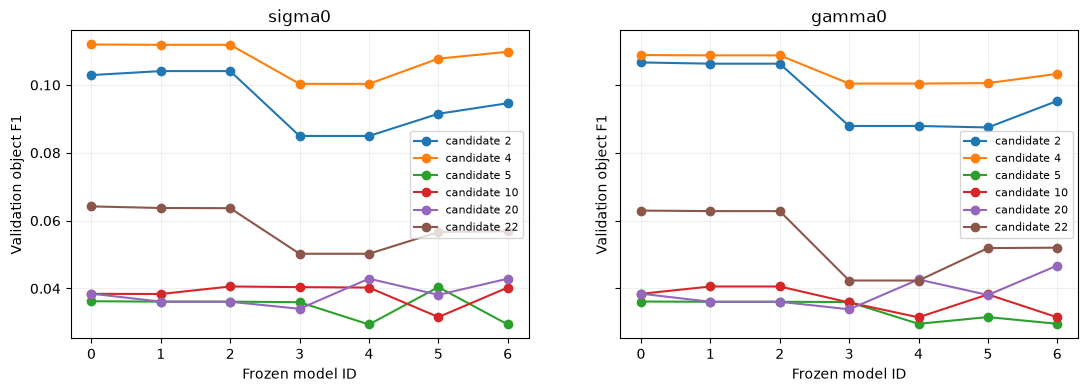

,max_abs_error,max_relative_error,mse
branch,,,
gamma0,1.011872e-08,5.955015e-08,9.440711e-20
sigma0,4.597900e-09,7.284338e-08,6.951667e-20


Original NumPy cross-checks: 48


In [3]:
fig, axes = plt.subplots(1,2, figsize=(13,4), sharey=True)
for ax, branch in zip(axes, ['sigma0','gamma0']):
    subset = table[(table.branch==branch) & table.eligible]
    for candidate, part in subset.groupby('candidate'):
        ax.plot(part.model, part.numpy_f1, 'o-', label=f'candidate {candidate}')
    ax.set(title=branch, xlabel='Frozen model ID', ylabel='Validation object F1')
    ax.legend(fontsize=8); ax.grid(alpha=.2)
plt.show()
feature_table = pd.DataFrame([{'branch':r['branch'], 'candidate':r['config_id'], 'sample':r['sample'],
                              **r['reference']} for r in features['rows']])
assert feature_table.allclose.all() and feature_table.partition_match.all()
display(feature_table.groupby('branch')[['max_abs_error','max_relative_error','mse']].max())
print('Original NumPy cross-checks:', sum('original_numpy_check' in r for r in features['rows']))
assert all(r.get('original_numpy_check', True) for r in features['rows'])


## Đánh giá cuối trên test đã khóa

Không lọc GT nhỏ. Ghép một-một IoU ≥0,5. Số đối tượng là thành phần liên thông
trong từng tile, không phải số sự kiện dầu tràn độc nhất. Các tile trong cùng
cảnh có thể chứa lại một đối tượng.


In [4]:
test_ids = {r['sample'] for r in manifest['samples'] if r['split']=='test'}
summary = []
for role,r in evaluation['roles'].items():
    assert {i['sample'] for i in r['per_image']} == test_ids
    for backend in ['numpy','reference']:
        assert summarize([i['counts'][backend] for i in r['per_image']]) == r['metrics'][backend]
    summary.append({'role':role, **r['metrics']['numpy'], 'different_pixels':r['mask_disagreement_pixels']})
display(pd.DataFrame(summary)[['role','images','precision','recall','f1','fp_per_image','pixel_iou','different_pixels']])


,role,images,precision,recall,f1,fp_per_image,pixel_iou,different_pixels
0,primary,25,0.149254,0.036697,0.058910,4.56,0.414351,0
1,gamma_unrestricted,25,0.149254,0.036697,0.058910,4.56,0.414351,0
2,sigma_unrestricted,25,0.157480,0.036697,0.059524,4.28,0.419603,0
3,sigma_adaptive,25,0.157480,0.036697,0.059524,4.28,0.419603,0
4,paired_sigma_same_model,25,0.149254,0.036697,0.058910,4.56,0.414354,0
5,filtered_adaptive,25,0.074866,0.025688,0.038251,6.92,0.323822,0
6,paired_sigma_filtered_model,25,0.074074,0.025688,0.038147,7.00,0.322023,0


## Ablation góc tới và bất định theo cảnh

Giữ cùng mô hình được train bằng gamma0, scaler, lọc và ngưỡng; chỉ đổi gamma0
thành sigma0. Hai winner tối ưu riêng không phải ablation cô lập góc tới.
Bootstrap ghép cặp theo toàn cảnh, 2.000 lượt. Với ít cảnh, khoảng tin cậy còn hạn chế.
CI chứa 0 không chứng minh có cải thiện; kết quả âm cũng phải giữ nguyên.


95% paired scene-bootstrap CI: [0.0, 0.0]
Undefined draws: 0


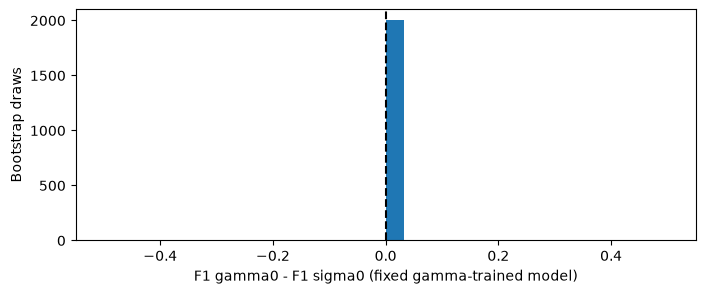

Required-filter detector 95% CI: [-0.00012903140425869764, 0.0002930420820639948]


In [5]:
rebuilt = scene_bootstrap(evaluation['roles']['primary']['per_image'],
                          evaluation['roles']['paired_sigma_same_model']['per_image'],
                          repeats=2000, seed=2026)
assert all(rebuilt[k] == bootstrap[k] for k in rebuilt)
print('95% paired scene-bootstrap CI:', rebuilt['ci95'])
print('Undefined draws:', rebuilt['undefined_draws'])
values = [v for v in rebuilt['gamma_minus_sigma_f1'] if v is not None]
fig, ax = plt.subplots(figsize=(8,3))
ax.hist(values, bins=30); ax.axvline(0,color='black',linestyle='--')
ax.set(xlabel='F1 gamma0 - F1 sigma0 (fixed gamma-trained model)', ylabel='Bootstrap draws')
plt.show()
filtered_bootstrap = json.loads((base/'angle_bootstrap_filtered.json').read_text())
filtered_rebuilt = scene_bootstrap(evaluation['roles']['filtered_adaptive']['per_image'],
                                  evaluation['roles']['paired_sigma_filtered_model']['per_image'])
assert all(filtered_rebuilt[k]==filtered_bootstrap[k] for k in filtered_rebuilt)
assert evaluation['angle_bootstrap_filtered_sha256']==sha(base/'angle_bootstrap_filtered.json')
print('Required-filter detector 95% CI:', filtered_bootstrap['ci95'])


## Chạy lại ảnh test đầu tiên theo ID

Không chọn ảnh theo điểm đẹp. Hàm suy luận chỉ đọc bức xạ và góc tới;
GT được đọc riêng sau suy luận để tính lại metric.


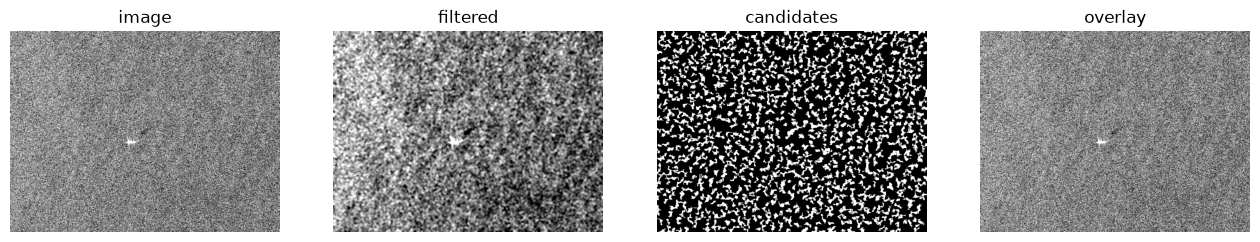

IMG_07_TILE_001 {'tp': 0, 'fp': 0, 'fn': 5, 'images': 1, 'empty_images': 0, 'intersection': 0, 'union': 221, 'predicted_pixels': 0, 'truth_pixels': 221, 'edge_gt': 0, 'edge_tp': 0, 'interior_gt': 5, 'interior_tp': 0, 'precision': None, 'recall': 0.0, 'f1': 0.0, 'pixel_iou': 0.0, 'dice': 0.0, 'fp_per_image': 0.0, 'edge_recall': None, 'interior_recall': 0.0}


,id,features,score,oil
0,1,"{'area_fraction': 0.0011881464914733017, 'elon...",-2.312353,False
1,2,"{'area_fraction': 0.0005110777187587364, 'elon...",-1.050429,False
2,3,"{'area_fraction': 0.00029266843723790885, 'elo...",-1.051942,False
3,4,"{'area_fraction': 0.0013213761532010063, 'elon...",-1.946327,False
4,5,"{'area_fraction': 0.0004302662845960302, 'elon...",-1.276839,False
...,...,...,...,...
589,590,"{'area_fraction': 0.0002118570030752027, 'elon...",-1.394354,False
590,591,"{'area_fraction': 0.00015288649706457925, 'elo...",-1.201908,False
591,592,"{'area_fraction': 0.00020530472462957787, 'elo...",-1.220422,False
592,593,"{'area_fraction': 0.00016380696114062063, 'elo...",-1.377371,False


In [6]:
sample = sorted(physical.samples(), key=lambda r:r['sample'])[0]
result = physical.run_sample(sample['sample'])
actual = physical.assess_sample(result)
saved = next(r for r in evaluation['roles']['filtered_adaptive']['per_image'] if r['sample']==sample['sample'])
assert actual['metrics'] == summarize([saved['counts']['numpy']])
assert not result['metadata']['ground_truth_used_for_inference']
fig, axes = plt.subplots(1,4, figsize=(16,4))
for ax, key in zip(axes, ['image','filtered','candidates','overlay']):
    ax.imshow(result[key], cmap='gray'); ax.set_title(key); ax.axis('off')
plt.show()
print(sample['sample'], actual['metrics'])
display(pd.DataFrame(result['metadata']['regions']))


## Giới hạn sử dụng

Cantarell là bằng chứng nhị phân dầu/nền có metadata vật lý, không thay thế
QPOSD về dầu/look-alike. ERA5 chỉ là bối cảnh, không làm nhãn nguyên nhân.
Gamma0 là hiệu chỉnh diện tích hình học; dữ liệu vẫn chưa xử lý thermal noise.
Kết quả không xác nhận khả năng cảnh báo tại biển miền Trung hoặc truy tìm tàu xả dầu.
